# Reproducing "Vision Transformers Need Registers" (Darcet et al.) at small scale (v2: 5 seeds, ViT-g Part 1, layer-wise check, significance tests)

This notebook has four parts:

| Part | What it does |
|---|---|
| Setup | imports, device, Imagenette loading (cached in GPU memory) |
| 1 | Detect high-norm *artifact* tokens in a pre-trained DINOv2 (no registers), optionally compare with the `_reg` variant |
| 2 | Custom small ViT with `num_registers` learnable tokens (appended after patch embedding, discarded before the head) |
| 3 | Train the ViT with `num_registers=0` and `num_registers=4` over several seeds, then linear-probe |
| 4 | Compare `[CLS]` attention maps, patch-token norms, and accuracies |

## Setup: environment, configuration, seeds

In [1]:
import os, sys, math, time, json, random, tarfile, urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = DEVICE.type == "cuda"
print("torch", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| GPUs visible:", torch.cuda.device_count(),
          "(this notebook uses GPU 0 only)")
else:
    print("WARNING: no GPU found. Enable it in Session options -> Accelerator, otherwise this will be very slow.")

OUT = Path("/kaggle/working") if os.path.exists("/kaggle/working") else Path("./outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

# ----------------------------- configuration -----------------------------
SEEDS      = [42, 43, 44, 45, 46]   # 5 seeds per configuration (more seeds = firmer statistics)
EPOCHS     = 40               # lower (e.g. 20) if you are short on time
BATCH      = 128
LR         = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 3
LABEL_SMOOTH = 0.1

IMG, PATCH = 128, 8           # 128/8 = 16 x 16 = 256 patch tokens
DIM, DEPTH, HEADS = 192, 6, 3 # ViT-Tiny-like width, half the depth
NUM_REG    = 4                # registers for the "with registers" model
CACHE_RES  = 144              # images cached at 144px, random-cropped to 128px

ARTIFACT_MODEL = "dinov2_vitg14"   # Part 1: the giant model used for the paper's main measurements (about 4.5 GB download)
THR_ABS = 150.0                    # absolute norm threshold used in the paper for DINOv2 ViT-g
THR_REL = 2.5                      # relative threshold: token norm > THR_REL x per-image median norm

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed(0)
torch.backends.cudnn.benchmark = True

torch 2.11.0+cu128 | device: cuda
GPU: Tesla T4 | GPUs visible: 2 (this notebook uses GPU 0 only)


### Load Imagenette
The cell below looks for any attached dataset under `/kaggle/input` that has a `train/` and a `val/` folder with 10 class folders.
If none is found, it falls back to downloading `imagenette2-160` from fast.ai (requires Internet ON).

In [2]:
def find_imagenette(root="/kaggle/input"):
    found = []
    if not os.path.isdir(root):
        return found
    for dp, dns, _ in os.walk(root):
        low = {d.lower(): d for d in dns}
        tr = low.get("train")
        va = low.get("val") or low.get("valid") or low.get("validation")
        if tr and va:
            trp, vap = os.path.join(dp, tr), os.path.join(dp, va)
            ncls = sum(os.path.isdir(os.path.join(trp, d)) for d in os.listdir(trp))
            if ncls == 10:
                found.append((trp, vap))
    return found


cands = find_imagenette()
if cands:
    TRAIN_DIR, VAL_DIR = cands[0]
    print("Found attached dataset:", TRAIN_DIR, "|", VAL_DIR)
else:
    print("No attached Imagenette found under /kaggle/input -> downloading imagenette2-160 ...")
    url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"
    dst = OUT / "imagenette2-160.tgz"
    urllib.request.urlretrieve(url, dst)
    with tarfile.open(dst) as tf:
        tf.extractall(OUT)
    TRAIN_DIR, VAL_DIR = str(OUT / "imagenette2-160" / "train"), str(OUT / "imagenette2-160" / "val")


def list_split(d):
    classes = sorted(c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c)))
    items = []
    for i, c in enumerate(classes):
        for f in sorted(os.listdir(os.path.join(d, c))):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                items.append((os.path.join(d, c, f), i))
    return classes, items


classes_tr, train_items = list_split(TRAIN_DIR)
classes_va, val_items = list_split(VAL_DIR)
assert classes_tr == classes_va and len(classes_tr) == 10, "train/val class folders do not match"
print(f"{len(classes_tr)} classes | train images: {len(train_items)} | val images: {len(val_items)}")
print("classes (WordNet ids):", classes_tr)

No attached Imagenette found under /kaggle/input -> downloading imagenette2-160 ...


/tmp/ipykernel_49/1686762319.py:27: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(OUT)


10 classes | train images: 9469 | val images: 3925
classes (WordNet ids): ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']


In [3]:
# Decode every image ONCE, resize (short side) + center-crop to CACHE_RES, keep as uint8 tensors on the GPU.
# This removes the CPU/JPEG bottleneck so each epoch takes seconds, not minutes.
class CacheDS(torch.utils.data.Dataset):
    def __init__(self, items, res):
        self.items, self.res = items, res
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        im = Image.open(p)
        im.draft("RGB", (self.res * 2, self.res * 2))   # fast JPEG downscale (no-op for non-JPEG)
        im = im.convert("RGB")
        w, h = im.size
        sc = self.res / min(w, h)
        im = im.resize((max(self.res, round(w * sc)), max(self.res, round(h * sc))), Image.BILINEAR)
        w, h = im.size
        l, t = (w - self.res) // 2, (h - self.res) // 2
        im = im.crop((l, t, l + self.res, t + self.res))
        return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1), y


def build_cache(items, res):
    dl = torch.utils.data.DataLoader(CacheDS(items, res), batch_size=256, num_workers=4, shuffle=False)
    xs, ys = [], []
    for x, y in tqdm(dl, leave=False):
        xs.append(x); ys.append(y)
    return torch.cat(xs), torch.cat(ys)


t0 = time.time()
Xtr, Ytr = build_cache(train_items, CACHE_RES)
Xva, Yva = build_cache(val_items, CACHE_RES)
Xtr, Ytr, Xva, Yva = Xtr.to(DEVICE), Ytr.to(DEVICE), Xva.to(DEVICE), Yva.to(DEVICE)
print(f"cached in {time.time()-t0:.0f}s | Xtr {tuple(Xtr.shape)} {Xtr.dtype} | Xva {tuple(Xva.shape)}")

MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1) * 255
STD_T = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1) * 255


def prep(xb_uint8):
    return (xb_uint8.float() - MEAN_T) / STD_T


def augment(xb):
    """Per-sample random 128px crop out of the 144px cache + random horizontal flip (on GPU)."""
    B, off = xb.size(0), CACHE_RES - IMG
    ix = torch.randint(0, off + 1, (B,)).tolist()
    iy = torch.randint(0, off + 1, (B,)).tolist()
    fl = (torch.rand(B) < 0.5).tolist()
    out = torch.empty(B, 3, IMG, IMG, dtype=xb.dtype, device=xb.device)
    for b in range(B):
        c = xb[b, :, iy[b]:iy[b] + IMG, ix[b]:ix[b] + IMG]
        out[b] = c.flip(-1) if fl[b] else c
    return out


def center(xb):
    o = (CACHE_RES - IMG) // 2
    return xb[:, :, o:o + IMG, o:o + IMG]

  0%|          | 0/37 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

cached in 9s | Xtr (9469, 3, 144, 144) torch.uint8 | Xva (3925, 3, 144, 144)


## Part 1: Artifact detection in a pre-trained DINOv2 (no registers)

We pass images through a pre-trained DINOv2 **without** registers, take the **final-layer patch tokens** (raw block output, *before* the last LayerNorm, which is where the norm outliers are most visible), and compute the L2 norm of every token.

Two outlier definitions are reported:
* **absolute**: norm > 150 (the threshold the paper uses for the large DINOv2 models);
* **relative**: norm > 2.5 x the image's median token norm (works regardless of model scale).

The images shown in the heatmaps are the ones with the **most** outliers (selected on purpose to show the effect; the pooled statistics are over all images).

In [4]:
tf224 = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224),
                   T.ToTensor(), T.Normalize(MEAN, STD)])

N_STATS = 64
rng = random.Random(0)
stat_items = rng.sample(val_items, N_STATS)
stat_imgs = torch.stack([tf224(Image.open(p).convert("RGB")) for p, _ in stat_items])   # (64, 3, 224, 224)


def denorm224(x):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (x * s + m).clamp(0, 1).permute(1, 2, 0).numpy()


def load_dino(name):
    try:
        m = torch.hub.load("facebookresearch/dinov2", name)
    except Exception as e:
        raise RuntimeError("Could not load DINOv2 via torch.hub. Is Internet turned ON in the notebook settings? "
                           f"Original error: {e}")
    return m.to(DEVICE).eval()


@torch.no_grad()
def dino_patch_norms(model, imgs, bs=16):
    outs = []
    for i in range(0, len(imgs), bs):
        x = imgs[i:i + bs].to(DEVICE)
        # final block output, patch tokens only (register tokens, if any, are already excluded), no final LayerNorm
        tok = model.get_intermediate_layers(x, n=1, norm=False)[0]       # (B, 256, D)
        outs.append(tok.float().norm(dim=-1).cpu())
    return torch.cat(outs)                                               # (N, 256)


def outlier_stats(norms):
    med = norms.median(dim=1, keepdim=True).values
    return {"median_norm": norms.median().item(), "max_norm": norms.max().item(),
            "frac_abs>150": (norms > THR_ABS).float().mean().item(),
            "frac_rel>2.5x_median": (norms > THR_REL * med).float().mean().item()}


PART1_OK = False
try:
    dino = load_dino(ARTIFACT_MODEL)
    norms_plain = dino_patch_norms(dino, stat_imgs)
    stats_plain = outlier_stats(norms_plain)
    print(f"{ARTIFACT_MODEL} (no registers):")
    for k, v in stats_plain.items():
        print(f"   {k:24s} {v:.4f}")
    PART1_OK = True
except Exception as e:
    print("Part 1 will be SKIPPED: could not download DINOv2 (turn Internet ON in session options and re-run this cell to enable it).")
    print("Reason:", str(e)[:300])

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitg14/dinov2_vitg14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitg14_pretrain.pth


100%|██████████| 4.23G/4.23G [00:11<00:00, 391MB/s]


dinov2_vitg14 (no registers):
   median_norm              49.0946
   max_norm                 542.8008
   frac_abs>150             0.0288
   frac_rel>2.5x_median     0.0288


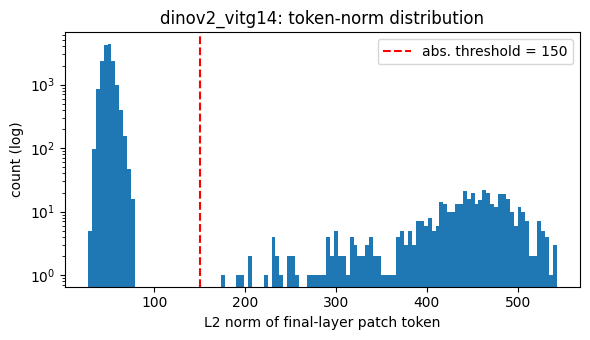

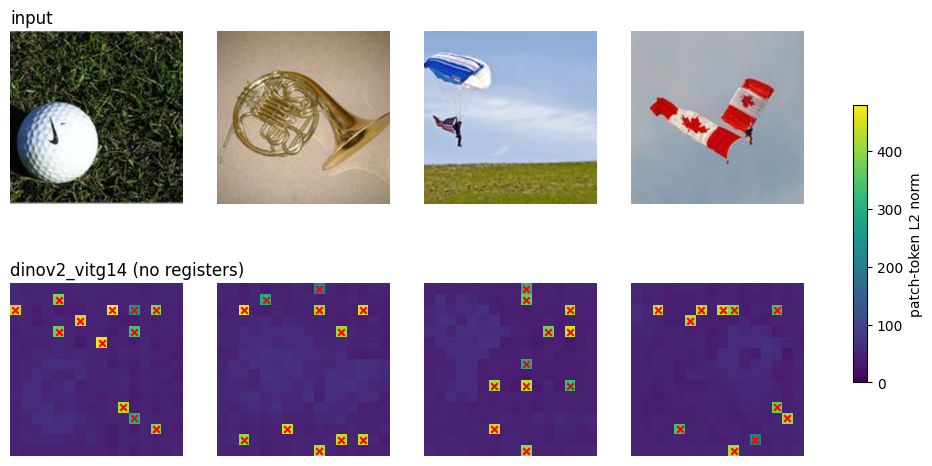

In [5]:
if PART1_OK:
    # Histogram of token norms (pooled over the 64 images) + heatmaps for the images with most outliers.
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist(norms_plain.flatten().numpy(), bins=120, color="tab:blue")
    ax.set_yscale("log"); ax.axvline(THR_ABS, color="red", ls="--", label=f"abs. threshold = {THR_ABS:.0f}")
    ax.set_xlabel("L2 norm of final-layer patch token"); ax.set_ylabel("count (log)")
    ax.set_title(f"{ARTIFACT_MODEL}: token-norm distribution"); ax.legend()
    plt.tight_layout(); plt.savefig(OUT / "figures" / "part1_norm_histogram.png", dpi=200); plt.show()


    def show_norm_grid(img_ids, panels, fname):
        cols, rows = len(img_ids), 1 + len(panels)
        fig, axs = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.0 * rows), squeeze=False)
        vmax = max(nr[img_ids].max().item() for _, nr in panels)
        im = None
        for j, i in enumerate(img_ids):
            axs[0, j].imshow(denorm224(stat_imgs[i])); axs[0, j].axis("off")
            if j == 0: axs[0, j].set_title("input", loc="left")
            for r, (label, nr) in enumerate(panels, 1):
                g = int(math.sqrt(nr.shape[1]))
                m = nr[i].reshape(g, g).numpy()
                im = axs[r, j].imshow(m, cmap="viridis", vmin=0, vmax=vmax)
                med = np.median(m)
                ys, xs = np.where(m > THR_REL * med)
                axs[r, j].scatter(xs, ys, marker="x", c="red", s=22)       # red x = relative-threshold outliers
                axs[r, j].axis("off")
                if j == 0: axs[r, j].set_title(label, loc="left")
        fig.colorbar(im, ax=axs, shrink=0.6, label="patch-token L2 norm")
        plt.savefig(OUT / "figures" / fname, dpi=200, bbox_inches="tight"); plt.show()


    n_out = (norms_plain > THR_REL * norms_plain.median(dim=1, keepdim=True).values).sum(1)
    top_ids = n_out.topk(4).indices.tolist()
    show_norm_grid(top_ids, [(f"{ARTIFACT_MODEL} (no registers)", norms_plain)], "part1_norm_heatmaps_noreg.png")
else:
    print('Part 1 skipped (DINOv2 not available).')

### Part 1b (optional): the same images through DINOv2 **with** registers
The paper's central qualitative result: the `_reg` model should not show the high-norm outliers. If this cell fails (e.g. weights unavailable), the rest of the notebook is unaffected.

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitg14/dinov2_vitg14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitg14_reg4_pretrain.pth


100%|██████████| 4.23G/4.23G [03:48<00:00, 19.9MB/s]


dinov2_vitg14_reg:
   median_norm              106.0525
   max_norm                 221.1797
   frac_abs>150             0.0278
   frac_rel>2.5x_median     0.0000


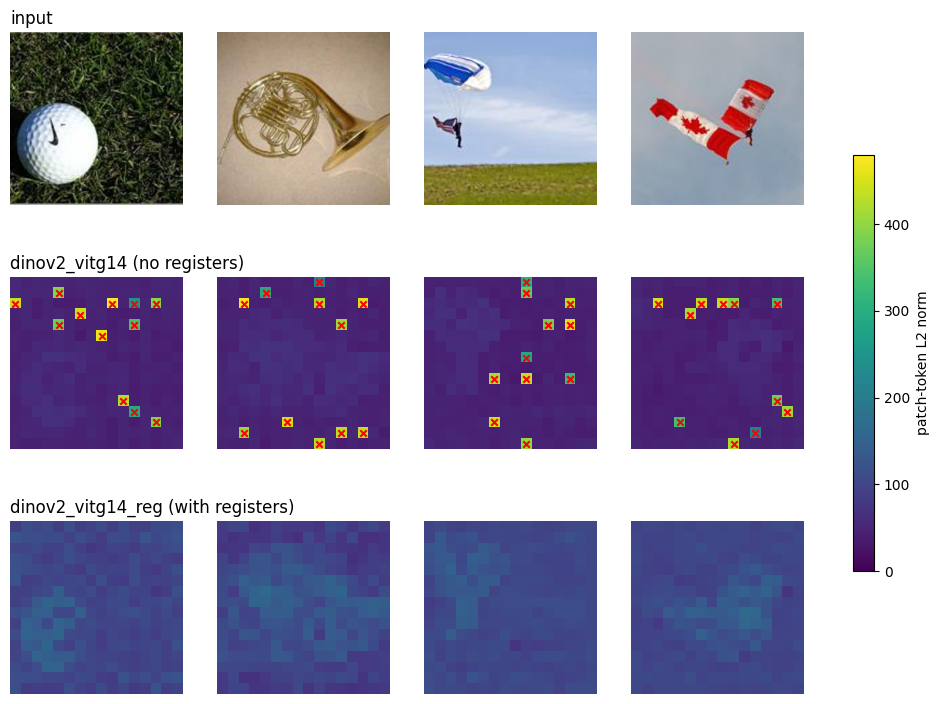

In [6]:
if PART1_OK:
    try:
        reg_name = ARTIFACT_MODEL + "_reg"
        del dino; torch.cuda.empty_cache()
        dino_reg = load_dino(reg_name)
        norms_reg = dino_patch_norms(dino_reg, stat_imgs)
        stats_reg = outlier_stats(norms_reg)
        print(f"{reg_name}:")
        for k, v in stats_reg.items():
            print(f"   {k:24s} {v:.4f}")
        show_norm_grid(top_ids, [(f"{ARTIFACT_MODEL} (no registers)", norms_plain),
                                 (f"{reg_name} (with registers)", norms_reg)], "part1_norm_heatmaps_reg_vs_noreg.png")
        with open(OUT / "part1_stats.json", "w") as f:
            json.dump({ARTIFACT_MODEL: stats_plain, reg_name: stats_reg}, f, indent=2)
        del dino_reg; torch.cuda.empty_cache()
    except Exception as e:
        print("Part 1b skipped:", e)
else:
    print('Part 1 skipped (DINOv2 not available).')

### Part 1c: layer-wise norm diagnostic
The paper reports that outliers start to appear around the middle layers. We measure the spread of patch-token norms (max / median) at several blocks of the pre-trained model to see whether any layer shows a separated outlier cluster.

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


block    median       max  frac>2.5x
    3       2.4       5.9     0.0016
    8       2.3       3.9     0.0000
   13       3.3       5.0     0.0000
   18       5.4      19.6     0.0112
   23       9.1     137.5     0.0281
   28      15.5     324.8     0.0288
   33      27.4     481.2     0.0288
   38      43.3     541.6     0.0288
   39      49.1     542.8     0.0288


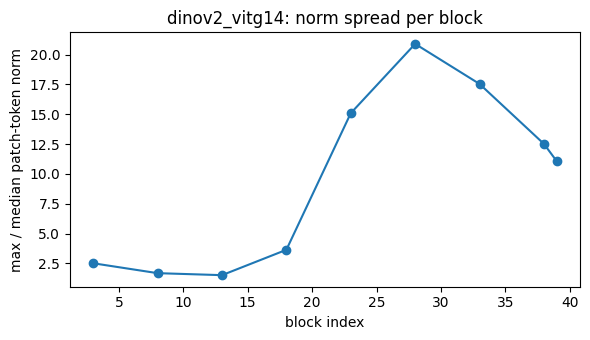

In [7]:
if PART1_OK:
    dino_diag = load_dino(ARTIFACT_MODEL)
    n_blocks = len(dino_diag.blocks)
    layer_ids = sorted(set(list(range(3, n_blocks, max(1, n_blocks // 8))) + [n_blocks - 1]))
    rows = []
    with torch.no_grad():
        for L in layer_ids:
            norms = []
            for i in range(0, len(stat_imgs), 8):
                x = stat_imgs[i:i + 8].to(DEVICE)
                tok = dino_diag.get_intermediate_layers(x, n=[L], norm=False)[0]
                norms.append(tok.float().norm(dim=-1).cpu())
            norms = torch.cat(norms)
            st = outlier_stats(norms)
            rows.append((L, st["median_norm"], st["max_norm"], st["frac_rel>2.5x_median"]))
    print(f"{'block':>5} {'median':>9} {'max':>9} {'frac>2.5x':>10}")
    for r in rows:
        print(f"{r[0]:>5} {r[1]:>9.1f} {r[2]:>9.1f} {r[3]:>10.4f}")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot([r[0] for r in rows], [r[2] / r[1] for r in rows], marker="o")
    ax.set_xlabel("block index"); ax.set_ylabel("max / median patch-token norm")
    ax.set_title(f"{ARTIFACT_MODEL}: norm spread per block")
    plt.tight_layout(); plt.savefig(OUT / "figures" / "part1c_layerwise_norm_ratio.png", dpi=200); plt.show()
    del dino_diag; torch.cuda.empty_cache()
else:
    print('Part 1 skipped (DINOv2 not available).')

## Part 2: Small ViT with register tokens

Token sequence handling (this is the whole method):

1. Patch-embed the image into `N` tokens, prepend `[CLS]`, add positional embeddings to `[CLS]` + patches.
2. **Append `R` learnable register tokens** *after* the positional embedding is added (registers have no position).
3. Run all `1 + N + R` tokens through the transformer blocks, so registers participate in attention at every layer.
4. **Discard the registers** (slice to the first `1 + N` tokens) before the head. Only `[CLS]` is used for classification.

With `num_registers=0` the model is a plain ViT.

In [8]:
class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.h = heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x, return_attn=False):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4)
        if return_attn:                                   # explicit softmax so we can inspect the weights
            a = ((q @ k.transpose(-2, -1)) * (q.shape[-1] ** -0.5)).softmax(-1)   # (B, H, N, N)
            out = a @ v
        else:                                             # fast fused path for training
            a = None
            out = F.scaled_dot_product_attention(q, k, v)
        return self.proj(out.transpose(1, 2).reshape(B, N, C)), a


class Block(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0):
        super().__init__()
        self.n1, self.attn = nn.LayerNorm(dim), Attention(dim, heads)
        self.n2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Linear(int(dim * mlp_ratio), dim))

    def forward(self, x, return_attn=False):
        h, a = self.attn(self.n1(x), return_attn)
        x = x + h
        x = x + self.mlp(self.n2(x))
        return x, a


class SmallViT(nn.Module):
    def __init__(self, img=IMG, patch=PATCH, dim=DIM, depth=DEPTH, heads=HEADS, num_classes=10, num_registers=0):
        super().__init__()
        self.grid = img // patch
        self.n = self.grid ** 2                 # number of patch tokens
        self.R = num_registers
        self.patch_embed = nn.Conv2d(3, dim, patch, patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, 1 + self.n, dim))          # positions for [CLS] + patches only
        self.reg = nn.Parameter(torch.zeros(1, num_registers, dim)) if num_registers > 0 else None
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        for p in [self.cls, self.pos] + ([self.reg] if self.reg is not None else []):
            nn.init.trunc_normal_(p, std=0.02)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)

    def forward_tokens(self, x, return_attn=False):
        """Returns ALL tokens (incl. registers) after the last block (before final norm) and last-layer attention."""
        B = x.shape[0]
        p = self.patch_embed(x).flatten(2).transpose(1, 2)                 # (B, N, D)
        x = torch.cat([self.cls.expand(B, -1, -1), p], dim=1) + self.pos   # (B, 1+N, D)
        if self.R > 0:
            x = torch.cat([x, self.reg.expand(B, -1, -1)], dim=1)          # (B, 1+N+R, D)  <- append registers
        attn = None
        for i, blk in enumerate(self.blocks):
            x, a = blk(x, return_attn and i == len(self.blocks) - 1)
            if a is not None:
                attn = a
        return x, attn

    def features(self, x):
        x, _ = self.forward_tokens(x)
        x = x[:, :1 + self.n]                  # <- DISCARD registers: keep [CLS] + patches only
        return self.norm(x[:, 0])              # classification uses [CLS]

    def forward(self, x):
        return self.head(self.features(x))


def make_model(R):
    return SmallViT(num_registers=R).to(DEVICE)


# ---- sanity checks ----
for R in (0, NUM_REG):
    m = make_model(R).eval()
    xb = torch.randn(2, 3, IMG, IMG, device=DEVICE)
    toks, attn = m.forward_tokens(xb, return_attn=True)
    assert toks.shape == (2, 1 + m.n + R, DIM), toks.shape
    assert attn.shape[-1] == 1 + m.n + R
    assert m(xb).shape == (2, 10)
    print(f"R={R}: tokens through blocks = {toks.shape[1]} (1 CLS + {m.n} patches + {R} registers) | "
          f"params = {sum(p.numel() for p in m.parameters())/1e6:.3f} M")
del m

R=0: tokens through blocks = 257 (1 CLS + 256 patches + 0 registers) | params = 2.758 M
R=4: tokens through blocks = 261 (1 CLS + 256 patches + 4 registers) | params = 2.759 M


## Part 3: Training and linear probing

For every seed we train two models from scratch: `num_registers=0` and `num_registers=4`, with identical hyper-parameters and the same starting seed (the register model draws extra random numbers for its registers, so initial weights and data order are not byte-identical).

* **Supervised val accuracy**: top-1 accuracy of the trained network (CLS -> linear head).
* **Linear-probe accuracy**: freeze the backbone, extract `[CLS]` features, fit a *new* linear classifier on the training features, evaluate on validation.

> Caveat: the paper linear-probes *self-supervised* DINOv2 features. Here the backbone is supervised-trained on the same 10 classes, so the probe mostly measures how linearly separable the learned `[CLS]` feature is. It is a scaled-down proxy, not the same experiment.

In [9]:
@torch.no_grad()
def evaluate(model, X, Y, bs=500):
    model.eval(); correct = 0
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        for i in range(0, len(X), bs):
            correct += (model(prep(center(X[i:i + bs]))).argmax(1) == Y[i:i + bs]).sum().item()
    return 100.0 * correct / len(X)


def train_model(R, seed, verbose=True):
    set_seed(seed)
    model = make_model(R)
    no_decay = [p for n, p in model.named_parameters() if p.ndim < 2 or n in ("cls", "pos", "reg")]
    decay = [p for n, p in model.named_parameters() if not (p.ndim < 2 or n in ("cls", "pos", "reg"))]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                             {"params": no_decay, "weight_decay": 0.0}], lr=LR)
    steps_per = len(Xtr) // BATCH
    total, warm = EPOCHS * steps_per, WARMUP_EPOCHS * steps_per
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = []
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        tl = torch.zeros((), device=DEVICE)
        for s in range(steps_per):
            idx = perm[s * BATCH:(s + 1) * BATCH]
            xb, yb = prep(augment(Xtr[idx])), Ytr[idx]
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                loss = F.cross_entropy(model(xb), yb, label_smoothing=LABEL_SMOOTH)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.detach()
        va = evaluate(model, Xva, Yva)
        hist.append({"epoch": ep + 1, "train_loss": (tl / steps_per).item(), "val_acc": va})
        if verbose and ((ep + 1) % 5 == 0 or ep == 0):
            print(f"  [R={R} seed={seed}] epoch {ep+1:3d}/{EPOCHS} | loss {hist[-1]['train_loss']:.3f} | val acc {va:.2f}%")
    return model, hist


@torch.no_grad()
def extract_features(model, X, bs=500):
    model.eval(); fs = []
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        for i in range(0, len(X), bs):
            fs.append(model.features(prep(center(X[i:i + bs]))).float())
    return torch.cat(fs)


def linear_probe(model, seed, steps=300):
    set_seed(seed)
    ftr, fva = extract_features(model, Xtr), extract_features(model, Xva)
    mu, sd = ftr.mean(0, keepdim=True), ftr.std(0, keepdim=True) + 1e-6
    ftr, fva = (ftr - mu) / sd, (fva - mu) / sd
    clf = nn.Linear(ftr.shape[1], 10).to(DEVICE)
    opt = torch.optim.AdamW(clf.parameters(), lr=1e-2, weight_decay=1e-3)
    for _ in range(steps):                                   # full-batch training of the linear classifier
        loss = F.cross_entropy(clf(ftr), Ytr)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return 100.0 * (clf(fva).argmax(1) == Yva).float().mean().item()

In [10]:
results, histories = [], {}
for seed in SEEDS:
    for R in (0, NUM_REG):
        print(f"=== seed {seed} | num_registers = {R} ===")
        t0 = time.time()
        model, hist = train_model(R, seed)
        sup = evaluate(model, Xva, Yva)
        probe = linear_probe(model, seed)
        results.append({"seed": seed, "num_registers": R, "supervised_val_acc": sup,
                        "linear_probe_val_acc": probe, "train_time_s": time.time() - t0})
        histories[(seed, R)] = hist
        torch.save(model.state_dict(), OUT / f"vit_reg{R}_seed{seed}.pt")
        with open(OUT / "results.json", "w") as f:                  # saved after every run so nothing is lost
            json.dump(results, f, indent=2)
        print(f"  -> supervised {sup:.2f}% | linear probe {probe:.2f}% | {time.time()-t0:.0f}s")
        del model; torch.cuda.empty_cache()

=== seed 42 | num_registers = 0 ===
  [R=0 seed=42] epoch   1/40 | loss 2.096 | val acc 35.18%
  [R=0 seed=42] epoch   5/40 | loss 1.476 | val acc 56.56%
  [R=0 seed=42] epoch  10/40 | loss 1.310 | val acc 63.92%
  [R=0 seed=42] epoch  15/40 | loss 1.209 | val acc 68.71%
  [R=0 seed=42] epoch  20/40 | loss 1.094 | val acc 71.82%
  [R=0 seed=42] epoch  25/40 | loss 0.995 | val acc 73.48%
  [R=0 seed=42] epoch  30/40 | loss 0.881 | val acc 75.69%
  [R=0 seed=42] epoch  35/40 | loss 0.794 | val acc 77.45%
  [R=0 seed=42] epoch  40/40 | loss 0.753 | val acc 77.30%
  -> supervised 77.30% | linear probe 76.76% | 345s
=== seed 42 | num_registers = 4 ===
  [R=4 seed=42] epoch   1/40 | loss 2.101 | val acc 32.64%
  [R=4 seed=42] epoch   5/40 | loss 1.484 | val acc 60.15%
  [R=4 seed=42] epoch  10/40 | loss 1.305 | val acc 62.24%
  [R=4 seed=42] epoch  15/40 | loss 1.197 | val acc 68.38%
  [R=4 seed=42] epoch  20/40 | loss 1.075 | val acc 69.71%
  [R=4 seed=42] epoch  25/40 | loss 0.957 | val ac

## Part 4: Ablation and comparison

Contents: (a) accuracy table (mean +/- std over seeds), (b) training curves, (c) `[CLS]` attention maps and patch-norm maps for both models on the same validation images, (d) quantitative artifact/attention metrics.

In [11]:
import pandas as pd

df = pd.DataFrame(results)


def ms(x):
    return float(np.mean(x)), (float(np.std(x, ddof=1)) if len(x) > 1 else 0.0)


lines = ["| Model | Supervised val acc (%) | Linear-probe val acc (%) | Seeds |", "|---|---|---|---|"]
summary = {}
for R in sorted(df.num_registers.unique()):
    d = df[df.num_registers == R]
    s_m, s_s = ms(d.supervised_val_acc.values); p_m, p_s = ms(d.linear_probe_val_acc.values)
    summary[R] = (s_m, s_s, p_m, p_s)
    lines.append(f"| Small ViT, {R} registers | {s_m:.2f} +/- {s_s:.2f} | {p_m:.2f} +/- {p_s:.2f} | {len(d)} |")
table_md = "\n".join(lines)
print(table_md)
(OUT / "results_table.md").write_text(table_md + "\n")

print("\nPer-run results:")
print(df.round(2).to_string(index=False))

d_sup = summary[NUM_REG][0] - summary[0][0]
d_pr = summary[NUM_REG][2] - summary[0][2]
noise = max(summary[0][1], summary[NUM_REG][1], summary[0][3], summary[NUM_REG][3])
print(f"\nDelta (registers - none): supervised {d_sup:+.2f} pts | linear probe {d_pr:+.2f} pts | max seed std {noise:.2f}")
from scipy import stats
for name, col in (("supervised", "supervised_val_acc"), ("linear probe", "linear_probe_val_acc")):
    a_ = df[df.num_registers == 0][col].values
    b_ = df[df.num_registers == NUM_REG][col].values
    w = stats.ttest_ind(b_, a_, equal_var=False)
    msg = f"{name}: delta {b_.mean() - a_.mean():+.2f} pts | Welch t = {w.statistic:.2f}, p = {w.pvalue:.3f} (n = {len(a_)} vs {len(b_)})"
    if len(a_) == len(b_) and len(a_) > 1:
        msg += f" | paired p = {stats.ttest_rel(b_, a_).pvalue:.3f}"
    print(msg)
print("Interpretation: p < 0.05 means the difference is unlikely to be seed noise; otherwise report 'no significant difference'.")
print("Report exactly what these numbers say, whichever direction they point.")

| Model | Supervised val acc (%) | Linear-probe val acc (%) | Seeds |
|---|---|---|---|
| Small ViT, 0 registers | 76.50 +/- 0.57 | 76.08 +/- 0.41 | 5 |
| Small ViT, 4 registers | 77.11 +/- 0.52 | 76.61 +/- 0.71 | 5 |

Per-run results:
 seed  num_registers  supervised_val_acc  linear_probe_val_acc  train_time_s
   42              0               77.30                 76.76        344.79
   42              4               76.54                 75.62        353.94
   43              0               76.48                 76.05        347.51
   43              4               76.74                 76.28        353.76
   44              0               76.69                 75.77        347.51
   44              4               77.45                 76.99        353.87
   45              0               75.72                 76.05        350.16
   45              4               77.81                 77.50        362.37
   46              0               76.33                 75.75        3

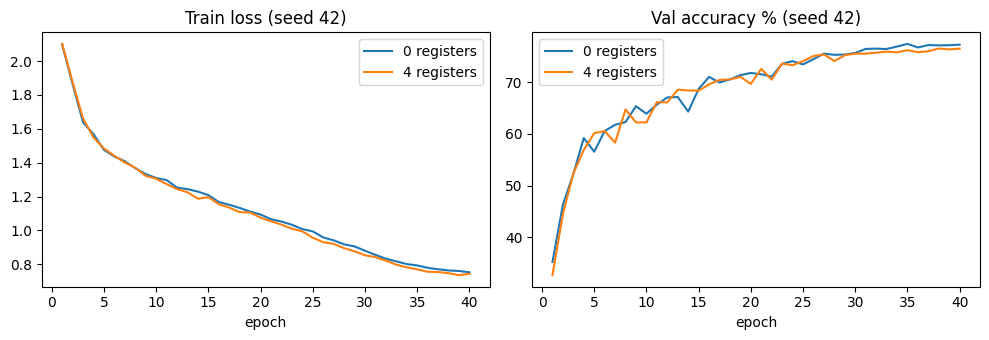

In [12]:
# Training curves (first seed)
s0 = SEEDS[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for R, c in ((0, "tab:blue"), (NUM_REG, "tab:orange")):
    h = histories[(s0, R)]
    ax[0].plot([e["epoch"] for e in h], [e["train_loss"] for e in h], c=c, label=f"{R} registers")
    ax[1].plot([e["epoch"] for e in h], [e["val_acc"] for e in h], c=c, label=f"{R} registers")
ax[0].set_title(f"Train loss (seed {s0})"); ax[1].set_title(f"Val accuracy % (seed {s0})")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "part4_training_curves.png", dpi=200); plt.show()

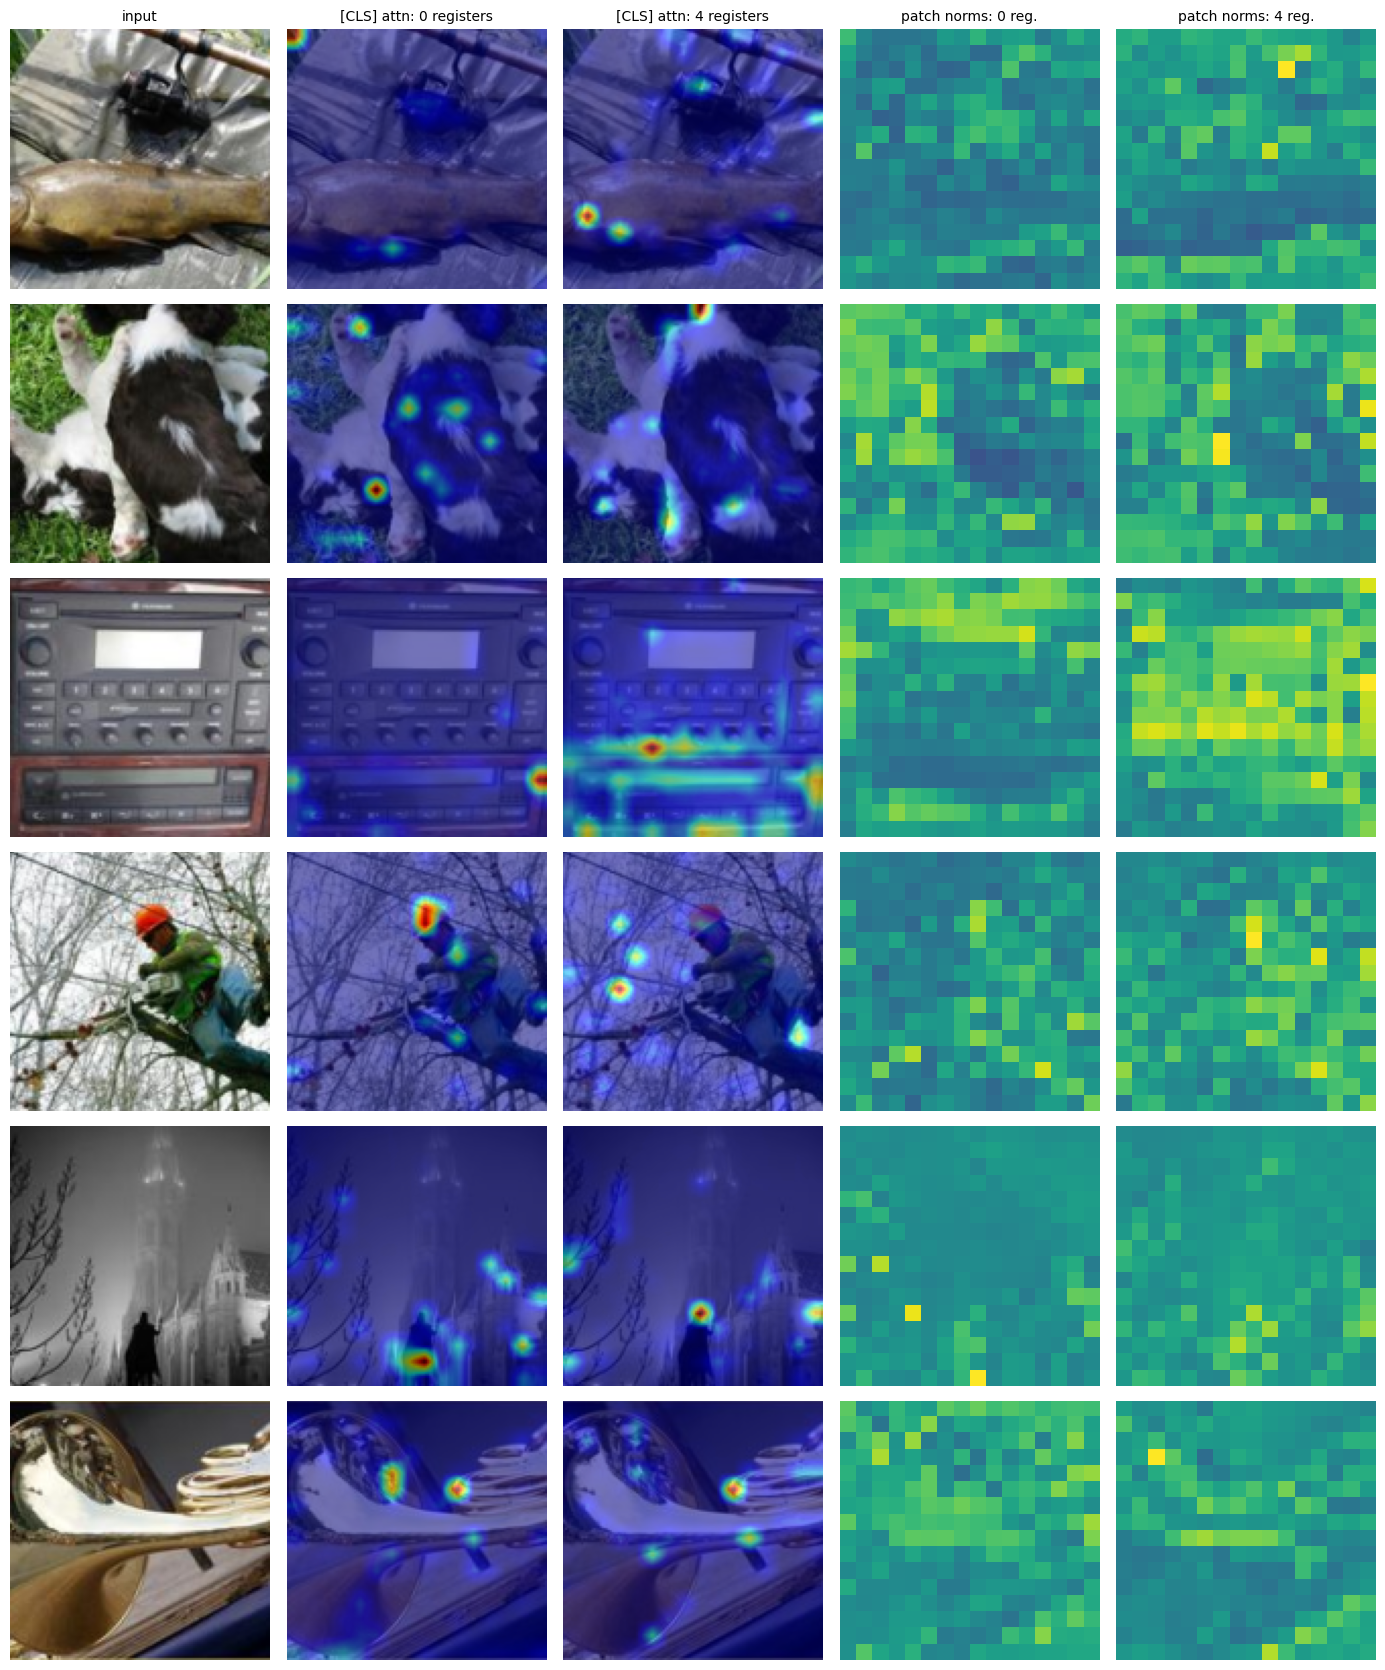

In [13]:
# Load the trained models of the first seed and visualise [CLS] attention (last layer, mean over heads) and patch-token norms.
models = {}
for R in (0, NUM_REG):
    m = make_model(R); m.load_state_dict(torch.load(OUT / f"vit_reg{R}_seed{s0}.pt", map_location=DEVICE)); models[R] = m.eval()


@torch.no_grad()
def cls_attn_and_norms(model, xb):
    toks, attn = model.forward_tokens(xb, return_attn=True)        # float32, no autocast
    n, g = model.n, model.grid
    a = attn[:, :, 0, 1:1 + n]                                      # [CLS] -> patches, (B, H, n)
    a_mean = a.mean(1).reshape(-1, g, g)
    reg_mass = attn[:, :, 0, 1 + n:].sum(-1).mean().item() if model.R > 0 else 0.0   # [CLS] attention given to registers
    norms = toks[:, 1:1 + n].norm(dim=-1).reshape(-1, g, g)         # patch tokens, last block output, pre-LayerNorm
    return a_mean.cpu(), a.cpu(), norms.cpu(), reg_mass


# one validation image from each of the first 6 classes (same images for both models)
vis_ids = [(Yva == c).nonzero()[0].item() for c in range(6)]
xb_uint8 = center(Xva[vis_ids])
xb = prep(xb_uint8)
out = {R: cls_attn_and_norms(models[R], xb) for R in models}

fig, axs = plt.subplots(len(vis_ids), 5, figsize=(14, 2.8 * len(vis_ids)))
titles = ["input", "[CLS] attn: 0 registers", f"[CLS] attn: {NUM_REG} registers", "patch norms: 0 reg.", f"patch norms: {NUM_REG} reg."]
for i in range(len(vis_ids)):
    img = xb_uint8[i].permute(1, 2, 0).cpu().numpy()
    axs[i, 0].imshow(img)
    for col, R in ((1, 0), (2, NUM_REG)):
        a = out[R][0][i:i + 1].unsqueeze(1)
        a = F.interpolate(a, size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0].numpy()
        a = (a - a.min()) / (a.max() - a.min() + 1e-8)
        axs[i, col].imshow(img); axs[i, col].imshow(a, cmap="jet", alpha=0.55)
    vmax = max(out[0][2][i].max().item(), out[NUM_REG][2][i].max().item())
    for col, R in ((3, 0), (4, NUM_REG)):
        axs[i, col].imshow(out[R][2][i].numpy(), cmap="viridis", vmin=0, vmax=vmax)
    for j in range(5):
        axs[i, j].axis("off")
        if i == 0: axs[i, j].set_title(titles[j], fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures" / "part4_attention_and_norm_maps.png", dpi=200); plt.show()

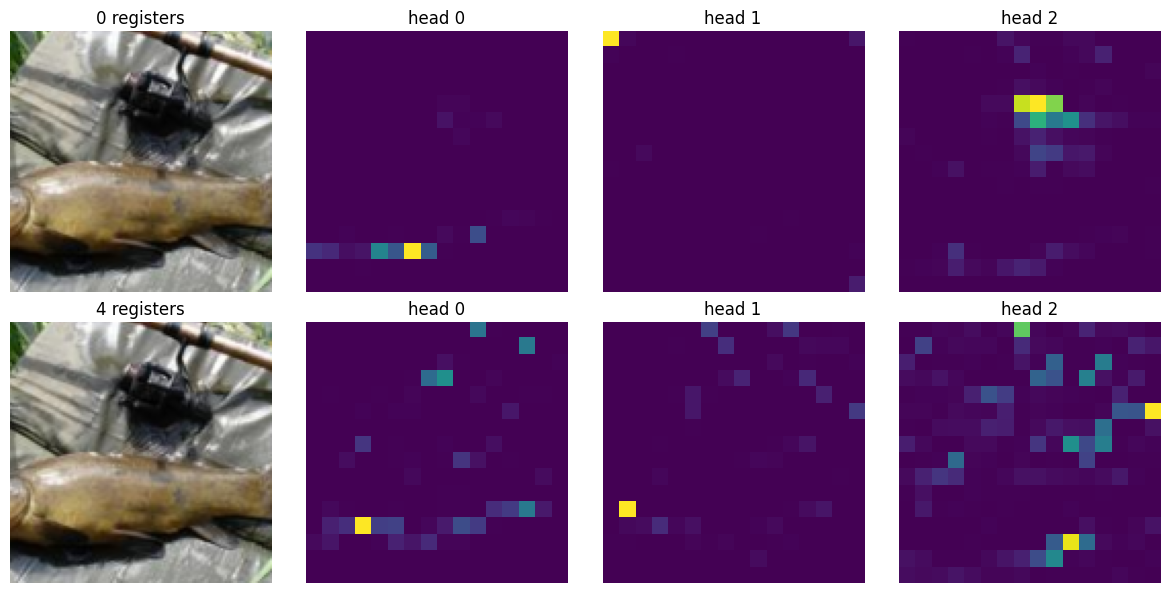

In [14]:
# Per-head [CLS] attention for a single image (last layer), both models
i0 = 0
fig, axs = plt.subplots(2, HEADS + 1, figsize=(3 * (HEADS + 1), 6))
img = xb_uint8[i0].permute(1, 2, 0).cpu().numpy()
for row, R in enumerate((0, NUM_REG)):
    axs[row, 0].imshow(img); axs[row, 0].set_title(f"{R} registers"); axs[row, 0].axis("off")
    for h in range(HEADS):
        a = out[R][1][i0, h].reshape(models[R].grid, models[R].grid).numpy()
        axs[row, h + 1].imshow(a, cmap="viridis"); axs[row, h + 1].set_title(f"head {h}"); axs[row, h + 1].axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures" / "part4_per_head_attention.png", dpi=200); plt.show()

In [15]:
# Quantitative metrics over 1000 validation images (first seed models):
#   outlier_frac    : fraction of patch tokens with norm > 2.5 x the image's median patch-token norm
#   max/median norm : mean over images of (max patch norm / median patch norm)
#   attn_entropy    : normalised entropy of the [CLS]->patch attention (1 = uniform, lower = more concentrated)
#   cls_to_registers: share of [CLS] attention (last layer) that goes to register tokens
NV = 1000
metrics = {}
for R in (0, NUM_REG):
    of, mx, ent, rm = [], [], [], []
    for i in range(0, NV, 250):
        xb_ = prep(center(Xva[i:i + 250]))
        a_mean, _, norms, reg_mass = cls_attn_and_norms(models[R], xb_)
        flat = norms.flatten(1)
        med = flat.median(dim=1, keepdim=True).values
        of.append((flat > THR_REL * med).float().mean().item())
        mx.append((flat.max(1).values / med.squeeze(1)).mean().item())
        p = a_mean.flatten(1); p = p / p.sum(1, keepdim=True)
        ent.append((-(p * (p + 1e-12).log()).sum(1) / math.log(p.shape[1])).mean().item())
        rm.append(reg_mass)
    metrics[R] = {"outlier_frac": float(np.mean(of)), "max_over_median_norm": float(np.mean(mx)),
                  "cls_attn_entropy_norm": float(np.mean(ent)), "cls_attn_to_registers": float(np.mean(rm))}
mdf = pd.DataFrame(metrics).T.rename_axis("num_registers")
print(mdf.round(4).to_string())
mdf.to_csv(OUT / "part4_metrics.csv")
print("\nIf outlier_frac is ~0 for BOTH models, the tiny ViT did not develop artifacts at this scale. That is an expected,"
      " reportable result: the paper finds artifacts only in large models trained long enough.")

               outlier_frac  max_over_median_norm  cls_attn_entropy_norm  cls_attn_to_registers
num_registers                                                                                  
0                    0.0000                1.7594                 0.7440                 0.0000
4                    0.0001                1.7024                 0.7768                 0.0065

If outlier_frac is ~0 for BOTH models, the tiny ViT did not develop artifacts at this scale. That is an expected, reportable result: the paper finds artifacts only in large models trained long enough.
